# 04. Kiểm chứng Dấu hiệu Tiền tắc nghẽn & Chốt Tham số Mô hình

> Phân tích chuyên sâu các dấu hiệu xuất hiện trước khi tắc nghẽn thực `(Speed < 40 mph & Occ ≥ 0.15)` bùng phát tại **Top 20 điểm nghẽn `PEMS08`** theo 5 bước tuần tự (dùng mốc mặc định là bước kế tiếp tự nhiên **`Δt = 5 phút`** ở Mục 3–5 để không giả định trước tầm dự báo, rồi chỉ chốt **`Δt*`** ở Mục 6): (1) Trực quan quỹ đạo pha tiền tắc nghẽn; (2) Xác định độ dài cửa sổ quá khứ `H*` bằng thống kê `PACF`; (3) Kiểm chứng độ biến động (`Δ` và `Std`) của từng biến `Flow / Occupancy / Speed` trong đúng `H*` bước; (4) Đánh giá giá trị cộng thêm của không gian đa nhánh (`Self only` vs `Self + Chiều vào`, `Self + Chiều ra`, `Self + 2 chiều`); (5) Gộp toàn bộ đặc trưng vào mô hình nhẹ để tìm tầm dự báo tối ưu `Δt*` cân bằng giữa `Δt` lớn nhất và sai số nhỏ nhất.

### Tóm tắt
* **Bối cảnh:** Kế thừa dữ liệu sạch `datasets/cleaned/PEMS08_clean.npz`, tiêu chí tắc nghẽn thực `(Speed < 40 mph & Occ ≥ 0.15)` và danh sách Top 20 điểm nghẽn (`outputs/PEMS08_bottlenecks.csv`) từ [03. Khám phá Dữ liệu Sạch (EDA) & Phân tích Điểm nghẽn (`03_EDA_and_Bottleneck_Analysis.ipynb`)](./03_EDA_and_Bottleneck_Analysis.ipynb).
* **Mục tiêu:** Chứng minh định lượng các tín hiệu tiền tắc nghẽn theo cả thời gian lẫn không gian và chốt dứt khoát bộ tham số đầu vào – đầu ra (`H*`, cấu trúc đồ thị 2 chiều đa nhánh, `Δt*` và dải kiểm thử) chuyển sang Bước 05.
* **Kết quả đầu ra:** `5` biểu đồ `300 DPI` tại `outputs/figures/nb04_*.png` và bộ tham số định lượng bàn giao cho [05. Thiết kế, Thử nghiệm Mô hình Dự báo & Giải thích Mô hình (`05_Modeling_and_Explainability.ipynb`)](./05_Modeling_and_Explainability.ipynb).

---
## 1. Thiết lập môi trường & Nạp dữ liệu sạch

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2, mannwhitneyu
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, log_loss, mean_absolute_error, r2_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import apply_congestion_rule, build_time_features, load_clean_pems

SEED = 42
np.random.seed(SEED)

CLEAN_DIR = ROOT / "datasets" / "cleaned"
RAW_DIR = ROOT / "datasets" / "data"
OUT_DIR = ROOT / "outputs"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SPEED_TH, OCC_TH = 40.0, 0.15
LEAD_DEFAULT = 1  # 1 bước đo tự nhiên = 5 phút (mặc định cho Mục 3–5 trước khi chốt Δt* ở Mục 6)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.edgecolor": "#CCCCCC"})

d8, edges8, bn_df8, bn_nodes8, bn_mask8 = load_clean_pems(
    "PEMS08", clean_dir=CLEAN_DIR, raw_dir=RAW_DIR, out_dir=OUT_DIR
)
T8, N8, _ = d8.shape
flw8, occ8, spd8 = d8[:, :, 0], d8[:, :, 1], d8[:, :, 2]
cg8 = apply_congestion_rule(spd8, occ8, SPEED_TH, OCC_TH)

G8 = nx.DiGraph()
G8.add_nodes_from(range(N8))
for r in edges8.itertuples(index=False):
    G8.add_edge(int(r[0]), int(r[1]), cost=float(r[2]))

# Khử nhịp trung bình theo khung giờ trong ngày (t % 288)
tod8 = d8.reshape(-1, 288, N8, 3).mean(axis=0)
res8 = (d8.reshape(-1, 288, N8, 3) - tod8).reshape(T8, N8, 3)

bn20 = [int(bn) for bn in bn_nodes8]
n_bidir = sum(1 for u, v in G8.edges() if G8.has_edge(v, u)) // 2
print(f"PEMS08 clean: {d8.shape} | Đồ thị: {G8.number_of_edges()} cạnh có hướng ({n_bidir} cặp 2 chiều, {G8.number_of_edges() - 2*n_bidir} cạnh 1 chiều)")
print(f"Top 20 điểm nghẽn: {bn20[:5]} ... (tổng {len(bn20)} trạm) | Tiêu chí tắc thực: Speed < {SPEED_TH} mph & Occ >= {OCC_TH} | Mốc mặc định Mục 3–5: Δt = {LEAD_DEFAULT*5}p")

PEMS08 clean: (17856, 170, 3) | Đồ thị: 277 cạnh có hướng (3 cặp 2 chiều, 271 cạnh 1 chiều)
Top 20 điểm nghẽn: [22, 14, 13, 9, 4] ... (tổng 20 trạm) | Tiêu chí tắc thực: Speed < 40.0 mph & Occ >= 0.15 | Mốc mặc định Mục 3–5: Δt = 5p


---
## 2. Trực quan hóa Khoảng thời gian Trước khi Xảy ra Tắc nghẽn (Quỹ đạo pha)

**Câu hỏi đặt ra:** *Trước khoảnh khắc một điểm nghẽn thực sự sụp pha vào trạng thái tắc nghẽn (`t = 0`), diễn biến trung bình của 3 biến vật lý `Lưu lượng`, `Độ chiếm dụng` và `Vận tốc` thay đổi ra sao trong cửa sổ từ `t - 60 phút` đến `t + 30 phút`?*

Số sự cố khởi phát tắc thực trên Top 20 điểm nghẽn: n = 3,136
  t = -60p | Flow = 428.3 | Occ = 0.176 | Speed = 49.2 mph
  t = -30p | Flow = 430.9 | Occ = 0.183 | Speed = 47.3 mph
  t = -20p | Flow = 432.5 | Occ = 0.185 | Speed = 46.5 mph
  t = -15p | Flow = 434.5 | Occ = 0.187 | Speed = 45.9 mph
  t = -10p | Flow = 435.2 | Occ = 0.192 | Speed = 44.7 mph
  t =  -5p | Flow = 431.4 | Occ = 0.204 | Speed = 42.5 mph
  t =  +0p | Flow = 407.5 | Occ = 0.253 | Speed = 36.9 mph


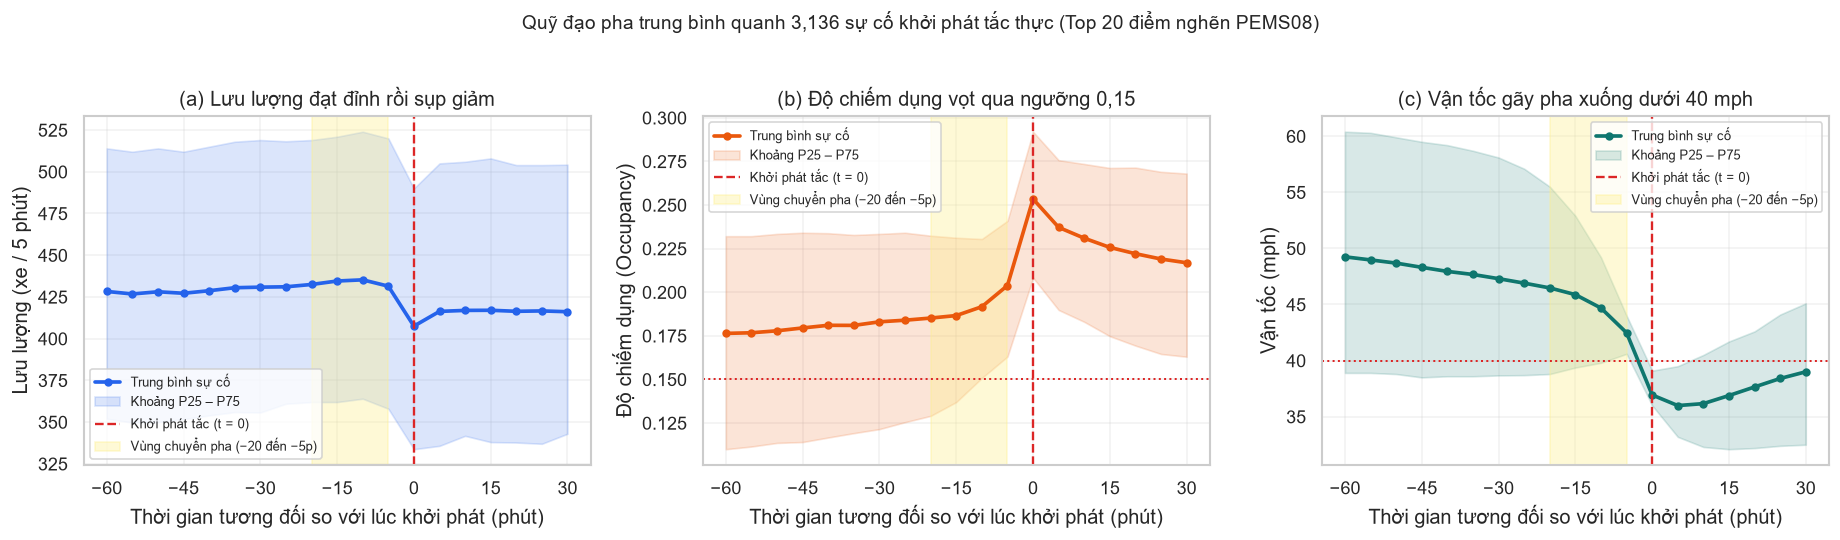

In [2]:
pre_steps, post_steps = 12, 6  # -60 phút đến +30 phút
win_len = pre_steps + post_steps + 1
rel_min = np.arange(-pre_steps, post_steps + 1) * 5

events = []
for bn in bn20:
    cg_n = cg8[:, bn]
    # Điểm khởi phát tắc thực: chưa tắc tại t-1 nhưng tắc tại t
    onsets = np.where(cg_n[1:] & (~cg_n[:-1]))[0] + 1
    for t0 in onsets:
        if t0 >= pre_steps and t0 + post_steps < T8:
            events.append(d8[t0 - pre_steps : t0 + post_steps + 1, bn, :])

ev_arr = np.asarray(events, dtype=np.float32)  # (n_events, win_len, 3)
ev_mean = ev_arr.mean(axis=0)
ev_p25 = np.percentile(ev_arr, 25, axis=0)
ev_p75 = np.percentile(ev_arr, 75, axis=0)

print(f"Số sự cố khởi phát tắc thực trên Top 20 điểm nghẽn: n = {len(ev_arr):,}")
for m_ref in [-60, -30, -20, -15, -10, -5, 0]:
    idx_m = int(np.where(rel_min == m_ref)[0][0])
    print(f"  t = {m_ref:+3d}p | Flow = {ev_mean[idx_m, 0]:5.1f} | Occ = {ev_mean[idx_m, 1]:.3f} | Speed = {ev_mean[idx_m, 2]:4.1f} mph")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
specs = [
    (0, "Lưu lượng (xe / 5 phút)", "#2563eb", None, "(a) Lưu lượng đạt đỉnh rồi sụp giảm"),
    (1, "Độ chiếm dụng (Occupancy)", "#ea580c", OCC_TH, "(b) Độ chiếm dụng vọt qua ngưỡng 0,15"),
    (2, "Vận tốc (mph)", "#0f766e", SPEED_TH, "(c) Vận tốc gãy pha xuống dưới 40 mph"),
]
for ax, (f_i, ylabel, col, th, ttl) in zip(axes, specs):
    ax.plot(rel_min, ev_mean[:, f_i], "o-", color=col, lw=2.2, markersize=4, label="Trung bình sự cố")
    ax.fill_between(rel_min, ev_p25[:, f_i], ev_p75[:, f_i], color=col, alpha=0.16, label="Khoảng P25 – P75")
    ax.axvline(0, color="#dc2626", ls="--", lw=1.4, label="Khởi phát tắc (t = 0)")
    ax.axvspan(-20, -5, color="#fef08a", alpha=0.35, label="Vùng chuyển pha (−20 đến −5p)")
    if th is not None:
        ax.axhline(th, color="#dc2626", ls=":", lw=1.2)
    ax.set(xlabel="Thời gian tương đối so với lúc khởi phát (phút)", ylabel=ylabel, title=ttl)
    ax.set_xticks([-60, -45, -30, -15, 0, 15, 30])
    ax.legend(fontsize=7.6, frameon=True)
    ax.grid(alpha=0.25)

fig.suptitle(f"Quỹ đạo pha trung bình quanh {len(ev_arr):,} sự cố khởi phát tắc thực (Top 20 điểm nghẽn PEMS08)", y=1.02, fontsize=11.5)
fig.tight_layout()
fig.savefig(FIG_DIR / "nb04_phase_trajectory.png", dpi=300, bbox_inches="tight")
plt.show()

> **Nhận xét (Quỹ đạo pha tiền tắc nghẽn trên `n = 3.136` sự cố khởi phát thực):**
>
> * **Tích tụ kéo dài trước khi sụp pha:** Từ `t = -60 phút` (`Flow = 428,3 xe/5p`, `Occ = 0,176`, `Speed = 49,2 mph`) đến `t = -20 phút` (`Flow = 432,5`, `Occ = 0,185`, `Speed = 46,5 mph`), dòng xe tích tụ mật độ đều đặn trong khi lưu lượng vẫn tiếp tục tăng nhẹ.
>
> * **Vùng chuyển pha quyết định (`t - 20` đến `t - 5` phút):** `Lưu lượng` đạt đỉnh công suất **`435,2 xe/5 phút`** tại **`t = -10 phút`** (`Occ = 0,192`, `Speed = 44,7 mph`), sau đó bắt đầu chững lại ở `t = -5 phút` (`Flow = 431,4`) trong khi `Độ chiếm dụng` tăng dựng đứng lên **`0,204`** và `Vận tốc` tụt nhanh xuống **`42,5 mph`**.
>
> * **Sụp pha tại `t = 0`:** Lưu lượng gãy mạnh xuống **`407,5 xe/5 phút`** (giảm `27,7 xe/5 phút` so với đỉnh ở `-10p`), `Độ chiếm dụng` vọt lên **`0,253`** và `Vận tốc` rơi qua ngưỡng tắc thực xuống **`36,9 mph`**. Tín hiệu báo trước đã xuất hiện rõ rệt ít nhất `15 – 20 phút` trước khi kẹt xe bùng phát.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Nhìn trực quan cho thấy dòng xe đã tích tụ từ vài chục phút trước khi gãy pha; vậy bằng kiểm định thống kê chuẩn, cần một cửa sổ quá khứ dài chính xác bao nhiêu bước (`H*`) để bao trọn các độ trễ mang thông tin trực tiếp cho sự cố tắc nghẽn?

---
## 3. Xác định Độ dài Cửa sổ Quá khứ Đủ dài (`H*` bước)

**Câu hỏi đặt ra:** *Trên chuỗi thời gian của Top 20 điểm nghẽn, cần nhìn ngược tối thiểu bao nhiêu bước (`H*`) để bao trọn các độ trễ mang thông tin trực tiếp trước khi tín hiệu hòa vào nhiễu nền?*

Ta dùng hai công cụ **thống kê thuần túy**:
* **Tự tương quan riêng phần `PACF(k)`** *(chuẩn Box–Jenkins đo lượng thông tin MỚI trực tiếp tại độ trễ $k$ sau khi đã loại ảnh hưởng gián tiếp từ $1 \dots k-1$; ngưỡng tin cậy `95%` cố định bằng toán học là $1,96 / \sqrt{T} = 0,0147$)*.
* **`ROC-AUC(t - k)` liên tục (`5 – 120 phút`)** đo sức mạnh phân tách ca sắp khởi phát tắc ở bước kế tiếp tự nhiên **`t + 5 phút`** (`1` bước đo) khi đoạn đường tại $t$ chưa tắc.

In [3]:
s20, o20, f20 = spd8[:, bn20], occ8[:, bn20], flw8[:, bn20]
cg20 = cg8[:, bn20]

def pacf_yule_walker(x: np.ndarray, nlags: int = 24) -> np.ndarray:
    x = x - x.mean()
    n = len(x)
    denom0 = float(np.dot(x, x))
    r = np.array([float(np.dot(x[:n - k], x[k:])) / denom0 for k in range(nlags + 1)])
    phi = np.zeros((nlags + 1, nlags + 1))
    phi[1, 1] = r[1]
    out = np.zeros(nlags)
    out[0] = r[1]
    for k in range(2, nlags + 1):
        num = r[k] - sum(phi[k - 1, j] * r[k - j] for j in range(1, k))
        den = 1.0 - sum(phi[k - 1, j] * r[j] for j in range(1, k))
        phi[k, k] = num / max(den, 1e-12)
        for j in range(1, k):
            phi[k, j] = phi[k - 1, j] - phi[k, k] * phi[k - 1, k - j]
        out[k - 1] = phi[k, k]
    return out

ci95 = 1.96 / np.sqrt(T8)
pacf_spd = np.mean([np.abs(pacf_yule_walker(s20[:, i], 24)) for i in range(len(bn20))], axis=0)
pacf_occ = np.mean([np.abs(pacf_yule_walker(o20[:, i], 24)) for i in range(len(bn20))], axis=0)

both_sig = (pacf_spd > ci95) & (pacf_occ > ci95)
BEST_H = 0
for idx_k, flag in enumerate(both_sig, start=1):
    if flag:
        BEST_H = idx_k
    else:
        break

lead_ref = LEAD_DEFAULT  # 5 phút (t + 1)
past_rows = []
for k in range(1, 25):
    t0, t1 = k, T8 - lead_ref
    cf = ~cg20[t0:t1]
    yf = cg20[t0 + lead_ref : t1 + lead_ref][cf].astype(int)
    past_rows.append({
        "k (bước)": k,
        "Khoảng (phút)": k * 5,
        "|PACF| Vận tốc": float(pacf_spd[k - 1]),
        "|PACF| Độ chiếm dụng": float(pacf_occ[k - 1]),
        "Vượt ngưỡng 95%": "Có" if (pacf_spd[k - 1] > ci95 and pacf_occ[k - 1] > ci95) else "Không",
        "AUC Occ(t-k)": float(roc_auc_score(yf, o20[t0 - k : t1 - k][cf])),
        "AUC Speed(t-k)": float(roc_auc_score(yf, -s20[t0 - k : t1 - k][cf])),
    })
past_df = pd.DataFrame(past_rows)
show_past = past_df[past_df["k (bước)"].isin([1, 2, 3, 4, 6, 7, 8, 9, 10, 12, 18, 24])].copy()
print(f"Bảng 3.1 — Kiểm định PACF (ngưỡng 95% = {ci95:.4f}) & ROC-AUC quá khứ (mốc t + {lead_ref*5}p) -> Chốt H* = {BEST_H} bước ({BEST_H*5} phút):")
print(show_past.round(4).to_string(index=False))
display(show_past.round(4))

Bảng 3.1 — Kiểm định PACF (ngưỡng 95% = 0.0147) & ROC-AUC quá khứ (mốc t + 5p) -> Chốt H* = 8 bước (40 phút):
 k (bước)  Khoảng (phút)  |PACF| Vận tốc  |PACF| Độ chiếm dụng Vượt ngưỡng 95%  AUC Occ(t-k)  AUC Speed(t-k)
        1              5          0.9770                0.9563              Có        0.9334          0.9438
        2             10          0.1685                0.2237              Có        0.9139          0.9110
        3             15          0.0413                0.0876              Có        0.9034          0.8918
        4             20          0.0220                0.0463              Có        0.8959          0.8778
        6             30          0.0201                0.0232              Có        0.8833          0.8579
        7             35          0.0158                0.0257              Có        0.8774          0.8477
        8             40          0.0160                0.0236              Có        0.8724          0.8392
        9         

,k (bước),Khoảng (phút),|PACF| Vận tốc,|PACF| Độ chiếm dụng,Vượt ngưỡng 95%,AUC Occ(t-k),AUC Speed(t-k)
0,1,5,0.9770,0.9563,Có,0.9334,0.9438
1,2,10,0.1685,0.2237,Có,0.9139,0.9110
2,3,15,0.0413,0.0876,Có,0.9034,0.8918
3,4,20,0.0220,0.0463,Có,0.8959,0.8778
5,6,30,0.0201,0.0232,Có,0.8833,0.8579
6,7,35,0.0158,0.0257,Có,0.8774,0.8477
7,8,40,0.0160,0.0236,Có,0.8724,0.8392
8,9,45,0.0142,0.0117,Không,0.8670,0.8299
9,10,50,0.0135,0.0140,Không,0.8620,0.8208
11,12,60,0.0153,0.0149,Có,0.8549,0.8112


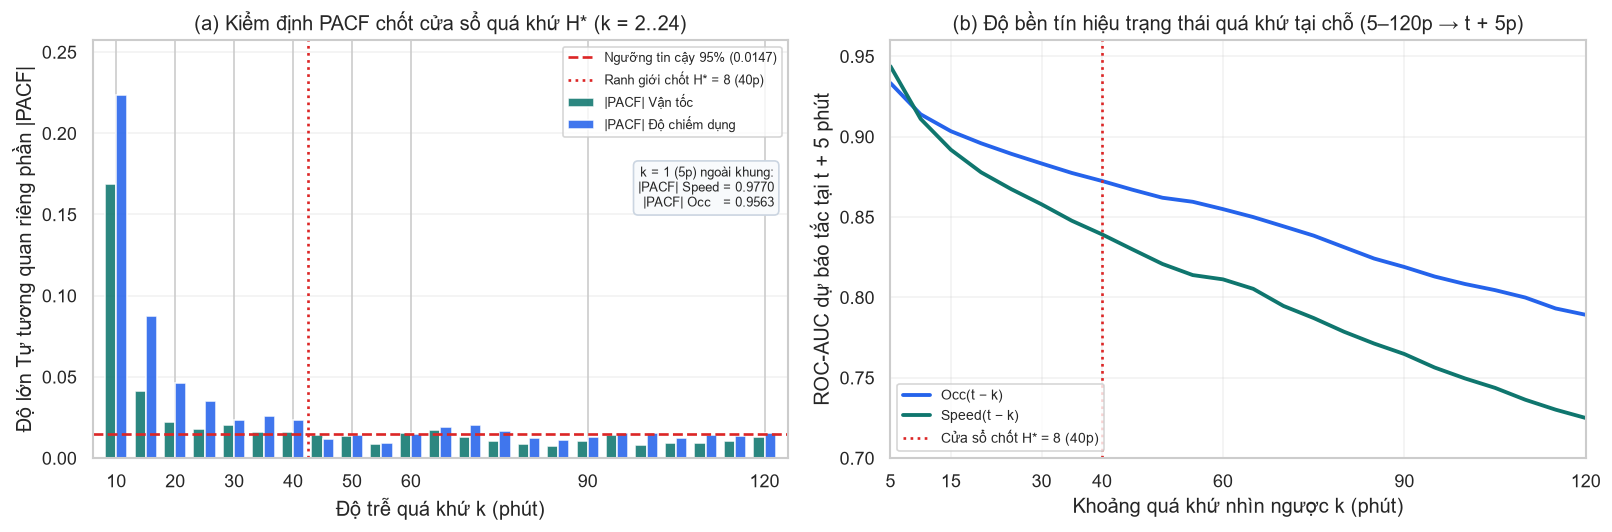

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.6))

ax = axes[0]
k_sub = past_df[past_df["k (bước)"] >= 2]
x_p = k_sub["Khoảng (phút)"].to_numpy()
w_p = 1.9
ax.bar(x_p - w_p / 2, k_sub["|PACF| Vận tốc"], width=w_p, color="#0f766e", alpha=0.88, label="|PACF| Vận tốc")
ax.bar(x_p + w_p / 2, k_sub["|PACF| Độ chiếm dụng"], width=w_p, color="#2563eb", alpha=0.88, label="|PACF| Độ chiếm dụng")
ax.axhline(ci95, color="#dc2626", ls="--", lw=1.6, label=f"Ngưỡng tin cậy 95% ({ci95:.4f})")
ax.axvline(BEST_H * 5 + 2.5, color="#dc2626", ls=":", lw=1.6, label=f"Ranh giới chốt H* = {BEST_H} ({BEST_H*5}p)")
ax.text(0.98, 0.70, f"k = 1 (5p) ngoài khung:\n|PACF| Speed = {pacf_spd[0]:.4f}\n|PACF| Occ   = {pacf_occ[0]:.4f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=8.0,
        bbox=dict(boxstyle="round,pad=0.35", fc="#f8fafc", ec="#cbd5e1"))
ax.set_xlim(6, 124); ax.set_xticks([10, 20, 30, 40, 50, 60, 90, 120])
ax.set_ylim(0, max(k_sub["|PACF| Độ chiếm dụng"]) * 1.15)
ax.set(xlabel="Độ trễ quá khứ k (phút)", ylabel="Độ lớn Tự tương quan riêng phần |PACF|",
       title="(a) Kiểm định PACF chốt cửa sổ quá khứ H* (k = 2..24)")
ax.legend(fontsize=7.8, loc="upper right", frameon=True)
ax.grid(axis="y", alpha=0.25)

ax = axes[1]
mins_k = past_df["Khoảng (phút)"]
ax.plot(mins_k, past_df["AUC Occ(t-k)"], "-", color="#2563eb", lw=2.3, label="Occ(t − k)")
ax.plot(mins_k, past_df["AUC Speed(t-k)"], "-", color="#0f766e", lw=2.3, label="Speed(t − k)")
ax.axvline(BEST_H * 5, color="#dc2626", ls=":", lw=1.6, label=f"Cửa sổ chốt H* = {BEST_H} ({BEST_H*5}p)")
ax.axhline(0.5, color="#94a3b8", ls=":", lw=1.0)
ax.set_xlim(5, 120); ax.set_xticks([5, 15, 30, 40, 60, 90, 120]); ax.set_ylim(0.70, 0.96)
ax.set(xlabel="Khoảng quá khứ nhìn ngược k (phút)", ylabel=f"ROC-AUC dự báo tắc tại t + {lead_ref*5} phút",
       title=f"(b) Độ bền tín hiệu trạng thái quá khứ tại chỗ (5–120p → t + {lead_ref*5}p)")
ax.legend(fontsize=8.2, loc="lower left", frameon=True)
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(FIG_DIR / "nb04_pacf_window_H.png", dpi=300, bbox_inches="tight")
plt.show()

> **Nhận xét (Chốt độ dài cửa sổ quá khứ `H* = 8` bước = `40 phút` bằng `PACF` & `ROC-AUC`):**
>
> * **Tự tương quan riêng phần `PACF` (ngưỡng tin cậy `95%` = `0,0147`):** Tại `k = 1` (`5p`), độ lớn `|PACF|` rất cao (`0,9770` với `Vận tốc` và `0,9563` với `Độ chiếm dụng`), tiếp tục duy trì ý nghĩa mạnh ở `k = 2` (`0,1685` / `0,2237`), `k = 3` (`0,0413` / `0,0876`), `k = 4` (`0,0220` / `0,0463`) và kéo dài **liên tục tới `k = 8` (`40 phút`)** (`0,0160` và `0,0236` — cả hai đều lớn hơn `0,0147`).
>
> * **Điểm cắt tự nhiên tại `k = 9` (`45 phút`):** Ngay tại `k = 9`, cả `|PACF| Vận tốc` (`0,0142`) lẫn `|PACF| Độ chiếm dụng` (`0,0117`) đều đồng thời rơi xuống dưới ngưỡng tin cậy `95%` (`0,0147`); từ `k = 10` đến `k = 24` chỉ còn dao động sát nền nhiễu biên (`k = 12` nhích biên `0,0153 / 0,0149` rồi giảm xuống `0,0107 / 0,0128` ở `k = 18`).
>
> * **Độ bền tín hiệu quá khứ (`ROC-AUC` báo bước kế tiếp `t + 5 phút`):** Trong toàn bộ cửa sổ `H* = 8` bước (`5 – 40 phút`), trạng thái quá khứ tại chỗ phân tách cực mạnh nhóm sắp khởi phát tắc: `AUC Occ(t - k)` giữ từ **`0,9334` đến `0,8724`** và `AUC Speed(t - k)` giữ từ **`0,9438` đến `0,8392`**.
>
> * **Kết luận chốt tham số:** Chốt độ dài chuỗi quá khứ đầu vào **`H* = 8` bước (`40 phút`)** hoàn toàn theo kiểm định thống kê chuẩn `PACF` (không chọn cảm tính).
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Trong chính cửa sổ quá khứ **`H* = 8` bước (`40 phút`)** vừa chốt, độ biến động (`Δ40p` dịch chuyển và `Std40p` dao động bất thường) của từng biến `Lưu lượng`, `Độ chiếm dụng` và `Vận tốc` có thể hiện rõ sự tăng vọt bất thường trước lúc tắc nghẽn (`t + 5 phút`) và mang giá trị nhận diện hay không?

---
## 4. Kiểm chứng Độ biến động của `Flow`, `Occupancy`, `Speed` trong Cửa sổ `H* = 8` (`40 phút`)

**Câu hỏi đặt ra:** *Khi đoạn đường tại $t$ vẫn **chưa tắc nghẽn**, trong đúng khoảng thời gian quá khứ **`H* = 8` bước (`40 phút`)** vừa chốt ở Mục 3, hai thước đo biến động của từng biến — **(1) Mức dịch chuyển $\Delta_{40p} = x_t - x_{t-8}$** và **(2) Độ lệch chuẩn dao động $\text{Std}_{40p}$** — có tăng bất thường ở nhóm sắp tắc tại bước kế tiếp (`t + 5 phút`) so với nhóm thông thoáng và có giá trị nhận diện tắc nghẽn hay không?*

In [5]:
ts_v = np.arange(BEST_H, T8 - lead_ref)
cf_v = ~cg20[ts_v]
yf_v = cg20[ts_v + lead_ref][cf_v].astype(int)

vol_rows = []
vol_plot_data = {}
for idx_f, fname, unit in [(0, "Lưu lượng (Flow)", "xe/5p"), (1, "Độ chiếm dụng (Occ)", "tỷ lệ"), (2, "Vận tốc (Speed)", "mph")]:
    arr = d8[:, bn20, idx_f]
    arr_res = res8[:, bn20, idx_f]
    win = np.stack([arr[ts_v - lag] for lag in range(BEST_H)], axis=0)
    delta_raw = (arr[ts_v] - arr[ts_v - BEST_H])[cf_v]
    delta_res = (arr_res[ts_v] - arr_res[ts_v - BEST_H])[cf_v]
    std_w = win.std(axis=0)[cf_v]

    score_d = -delta_raw if idx_f == 2 else delta_raw
    score_dr = -delta_res if idx_f == 2 else delta_res

    auc_d = float(roc_auc_score(yf_v, score_d))
    auc_dr = float(roc_auc_score(yf_v, score_dr))
    auc_std = float(roc_auc_score(yf_v, std_w))

    med1_d, med0_d = float(np.median(delta_raw[yf_v == 1])), float(np.median(delta_raw[yf_v == 0]))
    med1_s, med0_s = float(np.median(std_w[yf_v == 1])), float(np.median(std_w[yf_v == 0]))
    ratio_s = med1_s / max(med0_s, 1e-8)

    q90_s = float(np.quantile(std_w, 0.90))
    rr_s = float(yf_v[std_w >= q90_s].mean() / max(yf_v[std_w < q90_s].mean(), 1e-8))
    p_std = float(mannwhitneyu(std_w[yf_v == 1], std_w[yf_v == 0], alternative="greater").pvalue)

    vol_plot_data[fname] = {
        "auc_d": auc_d, "auc_dr": auc_dr, "auc_std": auc_std,
        "ratio_s": ratio_s, "rr_s": rr_s,
    }
    vol_rows.append({
        "Biến đo lường (trong H*=40p)": fname,
        "Δ40p TB vị (Sắp tắc / Thông)": f"{med1_d:+.4f} / {med0_d:+.4f}",
        "AUC Δ40p (gốc / khử ngày)": f"{auc_d:.4f} / {auc_dr:.4f}",
        "Std40p TB vị (Sắp tắc / Thông)": f"{med1_s:.4f} / {med0_s:.4f} ({ratio_s:.2f}x)",
        "AUC Std40p": round(auc_std, 4),
        "Risk Ratio Std Top10%": f"{rr_s:.2f}x",
        "p (Mann-Whitney)": "< 1e-300" if p_std < 1e-300 else f"{p_std:.2e}",
    })

vol_df = pd.DataFrame(vol_rows)
print(f"Bảng 4.1 — Kiểm chứng độ biến động của 3 biến trong đúng cửa sổ H* = {BEST_H} ({BEST_H*5} phút) trước tắc thực:")
print(vol_df.to_string(index=False))
display(vol_df)

Bảng 4.1 — Kiểm chứng độ biến động của 3 biến trong đúng cửa sổ H* = 8 (40 phút) trước tắc thực:
Biến đo lường (trong H*=40p) Δ40p TB vị (Sắp tắc / Thông) AUC Δ40p (gốc / khử ngày) Std40p TB vị (Sắp tắc / Thông)  AUC Std40p Risk Ratio Std Top10% p (Mann-Whitney)
            Lưu lượng (Flow)            +5.0000 / -2.0000           0.5315 / 0.5156      23.3024 / 18.2140 (1.28x)      0.6323                 2.06x         < 1e-300
         Độ chiếm dụng (Occ)            +0.0255 / -0.0006           0.6480 / 0.6165        0.0308 / 0.0058 (5.32x)      0.9321                35.96x         < 1e-300
             Vận tốc (Speed)            -4.9000 / +0.0000           0.6557 / 0.6316        4.2637 / 1.1252 (3.79x)      0.8715                12.28x         < 1e-300


,Biến đo lường (trong H*=40p),Δ40p TB vị (Sắp tắc / Thông),AUC Δ40p (gốc / khử ngày),Std40p TB vị (Sắp tắc / Thông),AUC Std40p,Risk Ratio Std Top10%,p (Mann-Whitney)
0,Lưu lượng (Flow),+5.0000 / -2.0000,0.5315 / 0.5156,23.3024 / 18.2140 (1.28x),0.6323,2.06x,< 1e-300
1,Độ chiếm dụng (Occ),+0.0255 / -0.0006,0.6480 / 0.6165,0.0308 / 0.0058 (5.32x),0.9321,35.96x,< 1e-300
2,Vận tốc (Speed),-4.9000 / +0.0000,0.6557 / 0.6316,4.2637 / 1.1252 (3.79x),0.8715,12.28x,< 1e-300


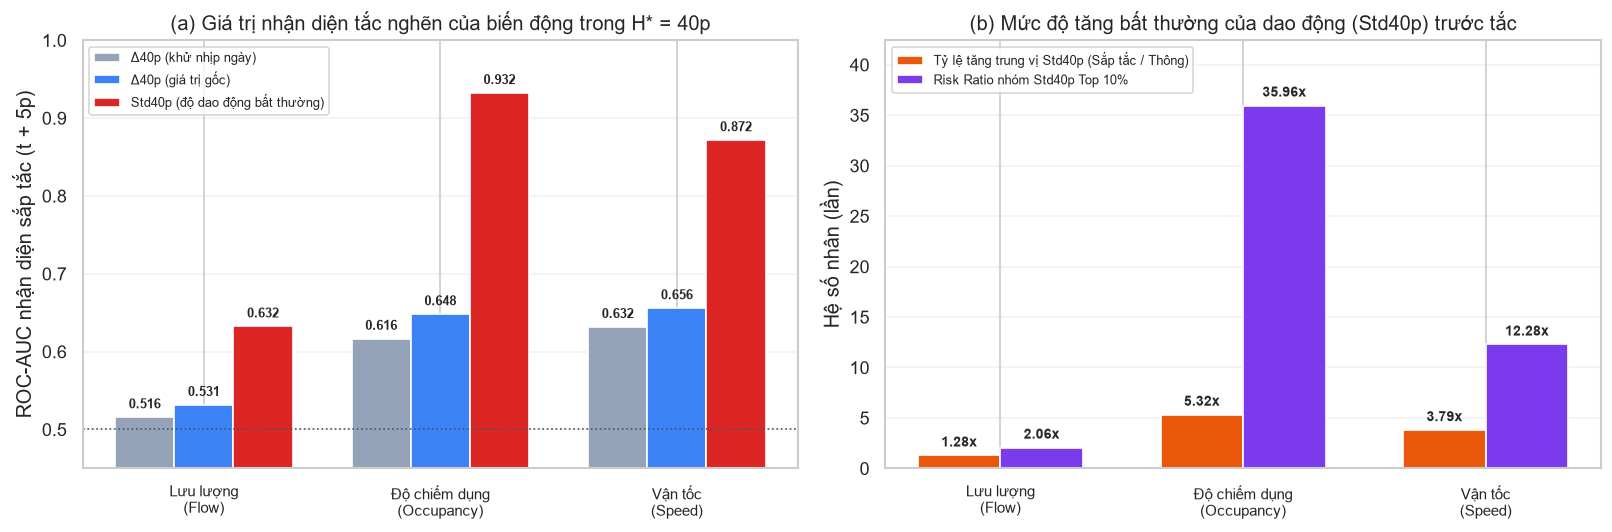

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.6))
v_names = list(vol_plot_data.keys())
short_names = ["Lưu lượng\n(Flow)", "Độ chiếm dụng\n(Occupancy)", "Vận tốc\n(Speed)"]
x_v = np.arange(len(v_names))
w_v = 0.25

# (a) ROC-AUC: Δ40p (khử ngày) vs Δ40p (gốc) vs Std40p (dao động bất thường)
ax = axes[0]
b1 = ax.bar(x_v - w_v, [vol_plot_data[k]["auc_dr"] for k in v_names], width=w_v, color="#94a3b8", label="Δ40p (khử nhịp ngày)")
b2 = ax.bar(x_v, [vol_plot_data[k]["auc_d"] for k in v_names], width=w_v, color="#3b82f6", label="Δ40p (giá trị gốc)")
b3 = ax.bar(x_v + w_v, [vol_plot_data[k]["auc_std"] for k in v_names], width=w_v, color="#dc2626", label="Std40p (độ dao động bất thường)")
ax.axhline(0.5, color="#475569", ls=":", lw=1.0)
for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.008, f"{h:.3f}", ha="center", va="bottom", fontsize=7.8, fontweight="bold")
ax.set_xticks(x_v); ax.set_xticklabels(short_names, fontsize=9.0)
ax.set_ylim(0.45, 1.00)
ax.set(ylabel=f"ROC-AUC nhận diện sắp tắc (t + {lead_ref*5}p)", title="(a) Giá trị nhận diện tắc nghẽn của biến động trong H* = 40p")
ax.legend(fontsize=7.8, loc="upper left", frameon=True)
ax.grid(axis="y", alpha=0.25)

# (b) Mức tăng vọt của Std40p (Hệ số tăng trung vị & Risk Ratio Top 10%)
ax = axes[1]
w2 = 0.34
b4 = ax.bar(x_v - w2 / 2, [vol_plot_data[k]["ratio_s"] for k in v_names], width=w2, color="#ea580c", label="Tỷ lệ tăng trung vị Std40p (Sắp tắc / Thông)")
b5 = ax.bar(x_v + w2 / 2, [vol_plot_data[k]["rr_s"] for k in v_names], width=w2, color="#7c3aed", label="Risk Ratio nhóm Std40p Top 10%")
for bars in [b4, b5]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.6, f"{h:.2f}x", ha="center", va="bottom", fontsize=8.3, fontweight="bold")
ax.set_xticks(x_v); ax.set_xticklabels(short_names, fontsize=9.0)
ax.set_ylim(0, max(vol_plot_data[k]["rr_s"] for k in v_names) * 1.18)
ax.set(ylabel="Hệ số nhân (lần)", title="(b) Mức độ tăng bất thường của dao động (Std40p) trước tắc")
ax.legend(fontsize=7.8, loc="upper left", frameon=True)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(FIG_DIR / "nb04_volatility_before_congestion.png", dpi=300, bbox_inches="tight")
plt.show()

> **Nhận xét (Kiểm chứng độ biến động của 3 biến trong đúng cửa sổ `H* = 8` bước = `40 phút`, mốc mặc định `t + 5 phút`):**
>
> * **`Độ chiếm dụng (Occupancy)` — biến động bất thường mạnh nhất:** Trước khi tắc ở bước kế tiếp (`t + 5p`), mức dịch chuyển trung vị `Δ40p` tăng dương rõ rệt (**`+0,0255`** so với `-0,0006` khi thông thoáng; `AUC Δ40p = 0,6480`, khử nhịp ngày vẫn đạt **`0,6165`**). Đặc biệt, độ dao động **`Std40p`** tăng vọt gấp **`5,32 lần`** (`0,0308` so với `0,0058`), đạt **`ROC-AUC = 0,9321`**, **`Risk Ratio Top 10% = 35,96x`** (`p < 1e-300` theo Mann–Whitney).
>
> * **`Vận tốc (Speed)` — tín hiệu biến động mạnh thứ hai:** `Δ40p` trung vị giảm sâu **`-4,9000 mph`** (so với `+0,0000 mph` lúc thông; `AUC = 0,6557`, khử nhịp ngày **`0,6316`**). Độ dao động **`Std40p`** tăng vọt gấp **`3,79 lần`** (`4,2637` so với `1,1252`), đạt **`ROC-AUC = 0,8715`**, **`Risk Ratio Top 10% = 12,28x`** (`p < 1e-300`).
>
> * **`Lưu lượng (Flow)` — tín hiệu phụ trợ yếu hơn nhưng vẫn có ý nghĩa:** `Δ40p` trung vị `+5,0000` so với `-2,0000` (`AUC = 0,5315 / 0,5156`); `Std40p` tăng **`1,28 lần`** (`23,3024` vs `18,2140`), `AUC = 0,6323`, `Risk Ratio = 2,06x` (`p < 1e-300`). Kết quả này nhất quán với tính đa trị gần đỉnh công suất của `Flow` đã phát hiện ở Bước 03.
>
> * **Hàm ý cho xây dựng đặc trưng:** Trước khi dòng xe sụp pha, không chỉ giá trị tức thời mà **biên độ dao động `Std40p` (hiện tượng xe chạy – dừng bất ổn)** của `Occupancy` và `Speed` tăng bất thường **`3,79 – 5,32 lần`**. Do đó, giữ trọn chuỗi `H* = 8` bước (cùng biến thiên `Δ` và `Std`) của cả 3 biến là hoàn toàn cần thiết.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Khi đã có đủ thông tin quá khứ `H* = 8` bước và độ biến động của chính điểm nghẽn (**`Self only`**), việc **bổ sung thêm không gian đồ thị đa nhánh** (`Self + Chiều vào`, `Self + Chiều ra`, `Self + 2 chiều`, xét cả phép gom `Mean`, `Max` và `Mean + Max` vì mỗi trạm nối nhiều nhánh vào/ra) có thực sự giúp cải thiện khả năng cảnh báo sớm vượt lên trên `Self only` hay không?

---
## 5. Đánh giá Giá trị Cộng thêm của Không gian Đa nhánh: `Self only` vs `Self + Chiều vào / Chiều ra / 2 chiều`

**Câu hỏi đặt ra:** *Do mỗi điểm nghẽn thường nối đồng thời với **nhiều nhánh đi vào** (`1–5` nhánh) và **nhiều nhánh đi ra** (`1–5` nhánh), nếu lấy **`Self only`** (bản thân điểm nghẽn đã có đủ lịch sử `H* = 8` và biến động `Δ40p / Std40p` từ Mục 3–4) làm nền rồi **cộng thêm trực tiếp** thông tin lân cận — **`Self + Chiều vào`**, **`Self + Chiều ra`**, và **`Self + 2 chiều`** (theo cả cách gom **`Mean`**, **`Max`**, và **`Mean + Max`**) — thì cấu trúc không gian nào cải thiện tốt nhất khả năng cảnh báo khởi phát tắc thực tại bước kế tiếp (`t + 5 phút`)?*

**Phương pháp đo chuẩn cho sự kiện hiếm (`~1%` khởi phát tắc):**
* Dùng **Hồi quy Logistic chuẩn dùng chung** (`70% Train / 15% Val` theo trục thời gian, không rò rỉ tương lai) trên `18 / 20` điểm nghẽn có đủ cả chiều vào và chiều ra.
* Do khởi phát tắc là sự kiện hiếm (`ROC-AUC` đã bão hòa quanh `0,98` nhờ `Self`), hai thước đo phản ánh chính xác nhất giá trị cộng thêm của không gian là **`Val PR-AUC`** *(Precision–Recall AUC — tập trung trực tiếp vào độ chính xác của các ca báo tắc thực)* và **`Val Log-Loss`** *(sai số xác suất kèm kiểm định **Likelihood-Ratio $\chi^2$ (`p-value`)** so sánh trực tiếp giữa các mô hình lồng nhau)*.

In [7]:
bn_2way = [int(bn) for bn in bn20
           if len([u for u in G8.predecessors(bn) if u != bn]) > 0
           and len([v for v in G8.successors(bn) if v != bn]) > 0]
K_bn = len(bn_2way)
in_degs = [len([u for u in G8.predecessors(bn) if u != bn]) for bn in bn_2way]
out_degs = [len([v for v in G8.successors(bn) if v != bn]) for bn in bn_2way]
print(f"Số điểm nghẽn có đủ cả chiều vào & chiều ra: {K_bn}/20 | Bậc vào: {min(in_degs)}–{max(in_degs)} (TB {np.mean(in_degs):.2f}) | Bậc ra: {min(out_degs)}–{max(out_degs)} (TB {np.mean(out_degs):.2f})")

t_tr, t_va = int(T8 * 0.70), int(T8 * 0.85)
ts0 = np.arange(BEST_H, T8)
i_tr = t_tr - BEST_H - lead_ref
i_va0, i_va1 = t_tr - BEST_H, t_va - BEST_H - lead_ref

cg_now_tr = cg8[BEST_H : BEST_H + i_tr][:, bn_2way]
cg_now_va = cg8[BEST_H + i_va0 : BEST_H + i_va1][:, bn_2way]
yc_tr = cg8[BEST_H + lead_ref : BEST_H + lead_ref + i_tr][:, bn_2way].astype(int)
yc_va = cg8[BEST_H + lead_ref + i_va0 : BEST_H + lead_ref + i_va1][:, bn_2way].astype(int)
cf_tr_flat = (~cg_now_tr).ravel()
cf_va_flat = (~cg_now_va).ravel()

def build_spatial_features(mode: str, agg: str) -> np.ndarray:
    blocks = []
    for bn in bn_2way:
        ups = sorted(u for u in G8.predecessors(bn) if u != bn)
        dns = sorted(v for v in G8.successors(bn) if v != bn)
        s, o, f = spd8[:, bn], occ8[:, bn], flw8[:, bn]
        s_w = np.stack([s[ts0 - l] for l in range(BEST_H)], axis=1)
        o_w = np.stack([o[ts0 - l] for l in range(BEST_H)], axis=1)
        f_w = np.stack([f[ts0 - l] for l in range(BEST_H)], axis=1)
        cols = [
            s[ts0], s[ts0 - 1], s[ts0 - 2], s[ts0] - s[ts0 - BEST_H], s_w.std(axis=1),
            o[ts0], o[ts0 - 1], o[ts0 - 2], o[ts0] - o[ts0 - BEST_H], o_w.std(axis=1),
            f[ts0], f[ts0] - f[ts0 - BEST_H], f_w.std(axis=1),
        ]
        def add_nbr(nbrs):
            c = []
            if agg in ("mean", "both"):
                c += [spd8[ts0][:, nbrs].mean(axis=1), occ8[ts0][:, nbrs].mean(axis=1), flw8[ts0][:, nbrs].mean(axis=1)]
            if agg in ("max", "both"):
                c += [spd8[ts0][:, nbrs].min(axis=1), occ8[ts0][:, nbrs].max(axis=1), flw8[ts0][:, nbrs].max(axis=1)]
            return c
        if mode in ("Self + Chiều vào", "Self + 2 chiều"):
            cols += add_nbr(ups)
        if mode in ("Self + Chiều ra", "Self + 2 chiều"):
            cols += add_nbr(dns)
        blocks.append(np.column_stack(cols))
    return np.stack(blocks, axis=1)

sp_configs = [
    ("Self only (Nền H* = 8)", "Self only", "both"),
    ("Self + Chiều vào (Mean)", "Self + Chiều vào", "mean"),
    ("Self + Chiều vào (Max)", "Self + Chiều vào", "max"),
    ("Self + Chiều vào (Mean + Max)", "Self + Chiều vào", "both"),
    ("Self + Chiều ra (Mean)", "Self + Chiều ra", "mean"),
    ("Self + Chiều ra (Max)", "Self + Chiều ra", "max"),
    ("Self + Chiều ra (Mean + Max)", "Self + Chiều ra", "both"),
    ("Self + 2 chiều (Mean)", "Self + 2 chiều", "mean"),
    ("Self + 2 chiều (Max)", "Self + 2 chiều", "max"),
    ("Self + 2 chiều (Mean + Max)", "Self + 2 chiều", "both"),
]

sp_results = {}
spatial_rows = []
n_va_free = int(cf_va_flat.sum())
for label, mode, agg in sp_configs:
    Fm = build_spatial_features(mode, agg)
    Xtr = Fm[:i_tr].reshape(-1, Fm.shape[-1])[cf_tr_flat]
    Xva_all = Fm[i_va0:i_va1].reshape(-1, Fm.shape[-1])
    sc = StandardScaler().fit(Xtr)
    lr = LogisticRegression(C=1.0, max_iter=400, random_state=SEED).fit(sc.transform(Xtr), yc_tr.ravel()[cf_tr_flat])
    p_va = lr.predict_proba(sc.transform(Xva_all))[:, 1].reshape(yc_va.shape)

    pr_all = float(average_precision_score(yc_va.ravel()[cf_va_flat], p_va.ravel()[cf_va_flat]))
    ll_all = float(log_loss(yc_va.ravel()[cf_va_flat], p_va.ravel()[cf_va_flat]))
    roc_all = float(roc_auc_score(yc_va.ravel()[cf_va_flat], p_va.ravel()[cf_va_flat]))
    node_lls = np.array([
        log_loss(yc_va[~cg_now_va[:, i], i], p_va[~cg_now_va[:, i], i], labels=[0, 1])
        for i in range(K_bn)
    ])
    sp_results[label] = {
        "pr": pr_all, "ll": ll_all, "roc": roc_all,
        "ll_sum": ll_all * n_va_free, "n_feat": Fm.shape[-1], "node_lls": node_lls,
    }

base_pr = sp_results["Self only (Nền H* = 8)"]["pr"]
base_ll_sum = sp_results["Self only (Nền H* = 8)"]["ll_sum"]
base_nf = sp_results["Self only (Nền H* = 8)"]["n_feat"]

for label, _, _ in sp_configs:
    r = sp_results[label]
    gain_pr = 100.0 * (r["pr"] - base_pr) / base_pr
    if label == "Self only (Nền H* = 8)":
        p_str = "— (Nền đối chiếu)"
    else:
        lrt = max(2.0 * (base_ll_sum - r["ll_sum"]), 0.0)
        p_val = float(chi2.sf(lrt, max(r["n_feat"] - base_nf, 1)))
        p_str = f"{p_val:.2e}" if p_val < 1e-4 else f"{p_val:.4f}"
    spatial_rows.append({
        "Cấu trúc không gian (t → t + 5p)": label,
        "Val PR-AUC": round(r["pr"], 4),
        "Tăng PR-AUC vs Self": f"{gain_pr:+.2f}%",
        "Val Log-Loss": round(r["ll"], 5),
        "Val ROC-AUC": round(r["roc"], 4),
        "p (LRT vs Self only)": p_str,
    })

def lrt_pair(better_lbl: str, base_lbl: str):
    rb, r0 = sp_results[better_lbl], sp_results[base_lbl]
    stat = max(2.0 * (r0["ll_sum"] - rb["ll_sum"]), 0.0)
    pval = float(chi2.sf(stat, max(rb["n_feat"] - r0["n_feat"], 1)))
    wins = int((rb["node_lls"] < r0["node_lls"]).sum())
    return stat, pval, wins

st_self, p_2w_self, w_self = lrt_pair("Self + 2 chiều (Mean + Max)", "Self only (Nền H* = 8)")
st_in, p_2w_in, w_in = lrt_pair("Self + 2 chiều (Mean + Max)", "Self + Chiều vào (Mean + Max)")
st_out, p_2w_out, w_out = lrt_pair("Self + 2 chiều (Mean + Max)", "Self + Chiều ra (Mean + Max)")

print(f"Kiểm định Likelihood-Ratio (Val 15%, n = {n_va_free:,} mẫu chưa tắc):")
print(f"  Self + 2 chiều > Self only      : chi2 = {st_self:5.1f}, p = {p_2w_self:.2e} (giảm Log-Loss tại {w_self}/{K_bn} điểm nghẽn)")
print(f"  Self + 2 chiều > Self + Chiều vào: chi2 = {st_in:5.1f}, p = {p_2w_in:.4f} (giảm Log-Loss tại {w_in}/{K_bn} điểm nghẽn)")
print(f"  Self + 2 chiều > Self + Chiều ra : chi2 = {st_out:5.1f}, p = {p_2w_out:.4f} (giảm Log-Loss tại {w_out}/{K_bn} điểm nghẽn)")

spatial_df = pd.DataFrame(spatial_rows)
print("\nBảng 5.1 — Đối chiếu giá trị cộng thêm của không gian đa nhánh so với Self only (mốc mặc định t + 5p):")
print(spatial_df.to_string(index=False))
display(spatial_df)

Số điểm nghẽn có đủ cả chiều vào & chiều ra: 18/20 | Bậc vào: 1–5 (TB 2.72) | Bậc ra: 1–5 (TB 2.44)
Kiểm định Likelihood-Ratio (Val 15%, n = 42,952 mẫu chưa tắc):
  Self + 2 chiều > Self only      : chi2 =  91.8, p = 2.26e-14 (giảm Log-Loss tại 13/18 điểm nghẽn)
  Self + 2 chiều > Self + Chiều vào: chi2 =  19.8, p = 0.0030 (giảm Log-Loss tại 12/18 điểm nghẽn)
  Self + 2 chiều > Self + Chiều ra : chi2 =  25.5, p = 0.0003 (giảm Log-Loss tại 9/18 điểm nghẽn)

Bảng 5.1 — Đối chiếu giá trị cộng thêm của không gian đa nhánh so với Self only (mốc mặc định t + 5p):
Cấu trúc không gian (t → t + 5p)  Val PR-AUC Tăng PR-AUC vs Self  Val Log-Loss  Val ROC-AUC p (LRT vs Self only)
          Self only (Nền H* = 8)      0.3094              +0.00%       0.02923       0.9805    — (Nền đối chiếu)
         Self + Chiều vào (Mean)      0.3108              +0.46%       0.02927       0.9804               1.0000
          Self + Chiều vào (Max)      0.3269              +5.66%       0.02857       0.9810      

,Cấu trúc không gian (t → t + 5p),Val PR-AUC,Tăng PR-AUC vs Self,Val Log-Loss,Val ROC-AUC,p (LRT vs Self only)
0,Self only (Nền H* = 8),0.3094,+0.00%,0.02923,0.9805,— (Nền đối chiếu)
1,Self + Chiều vào (Mean),0.3108,+0.46%,0.02927,0.9804,1.0000
2,Self + Chiều vào (Max),0.3269,+5.66%,0.02857,0.9810,2.29e-12
3,Self + Chiều vào (Mean + Max),0.3308,+6.92%,0.02839,0.9809,1.64e-13
4,Self + Chiều ra (Mean),0.3260,+5.38%,0.02848,0.9803,6.69e-14
5,Self + Chiều ra (Max),0.3230,+4.42%,0.02852,0.9805,4.07e-13
6,Self + Chiều ra (Mean + Max),0.3281,+6.04%,0.02846,0.9806,2.37e-12
7,Self + 2 chiều (Mean),0.3201,+3.46%,0.02881,0.9800,2.14e-06
8,Self + 2 chiều (Max),0.3288,+6.27%,0.02842,0.9808,4.24e-13
9,Self + 2 chiều (Mean + Max),0.3383,+9.36%,0.02816,0.9808,2.26e-14


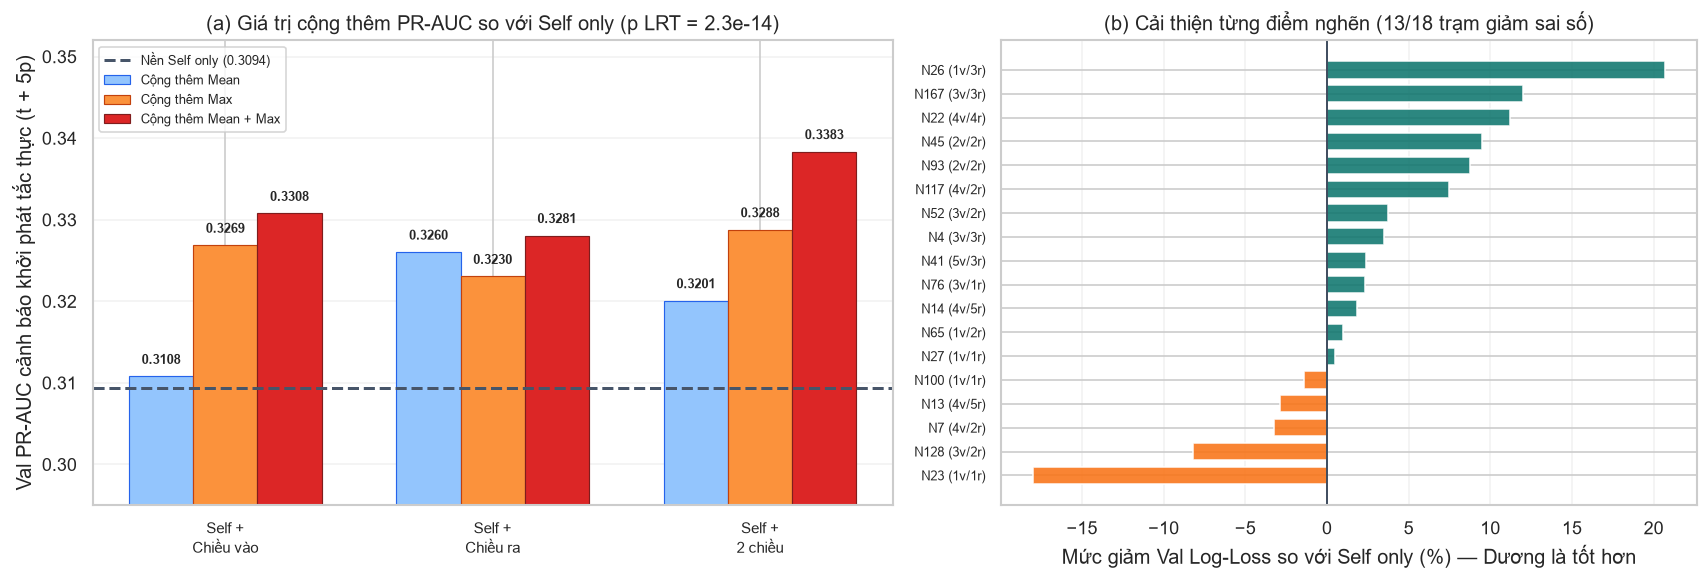

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14.4, 5.0), gridspec_kw={"width_ratios": [1.15, 1.0]})

# (a) Grouped bar chart Val PR-AUC: Self only vs Self + In / Out / 2-Way (Mean, Max, Mean+Max)
ax = axes[0]
groups = ["Self +\nChiều vào", "Self +\nChiều ra", "Self +\n2 chiều"]
x_g = np.arange(len(groups))
w_g = 0.24
v_mean = [sp_results[f"Self + {d} (Mean)"]["pr"] for d in ["Chiều vào", "Chiều ra", "2 chiều"]]
v_max = [sp_results[f"Self + {d} (Max)"]["pr"] for d in ["Chiều vào", "Chiều ra", "2 chiều"]]
v_both = [sp_results[f"Self + {d} (Mean + Max)"]["pr"] for d in ["Chiều vào", "Chiều ra", "2 chiều"]]

ax.axhline(base_pr, color="#475569", ls="--", lw=1.8, zorder=2, label=f"Nền Self only ({base_pr:.4f})")
b1 = ax.bar(x_g - w_g, v_mean, width=w_g, color="#93c5fd", edgecolor="#2563eb", lw=0.7, label="Cộng thêm Mean")
b2 = ax.bar(x_g, v_max, width=w_g, color="#fb923c", edgecolor="#c2410c", lw=0.7, label="Cộng thêm Max")
b3 = ax.bar(x_g + w_g, v_both, width=w_g, color="#dc2626", edgecolor="#7f1d1d", lw=0.7, label="Cộng thêm Mean + Max")

for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.0012, f"{h:.4f}", ha="center", va="bottom", fontsize=7.6, fontweight="bold")

ax.set_xticks(x_g); ax.set_xticklabels(groups, fontsize=9.2)
ax.set_ylim(0.295, 0.352)
ax.set(ylabel="Val PR-AUC cảnh báo khởi phát tắc thực (t + 5p)",
       title=f"(a) Giá trị cộng thêm PR-AUC so với Self only (p LRT = {p_2w_self:.1e})")
ax.legend(frameon=True, fontsize=7.8, loc="upper left")
ax.grid(axis="y", alpha=0.25)

# (b) Per-node % Log-Loss reduction of Self + 2-way (Mean+Max) vs Self only
ax = axes[1]
ll_self_n = sp_results["Self only (Nền H* = 8)"]["node_lls"]
ll_2w_n = sp_results["Self + 2 chiều (Mean + Max)"]["node_lls"]
pct_imp = 100.0 * (ll_self_n - ll_2w_n) / np.maximum(ll_self_n, 1e-8)
order_i = np.argsort(pct_imp)[::-1]
y_pos = np.arange(K_bn)
colors_b = ["#0f766e" if pct_imp[i] > 0 else "#f97316" for i in order_i]

ax.barh(y_pos, pct_imp[order_i], color=colors_b, alpha=0.88, height=0.72)
ax.axvline(0.0, color="#334155", lw=1.1)
ax.set_yticks(y_pos)
ax.set_yticklabels([f"N{bn_2way[i]} ({in_degs[i]}v/{out_degs[i]}r)" for i in order_i], fontsize=7.8)
ax.invert_yaxis()
ax.set(xlabel="Mức giảm Val Log-Loss so với Self only (%) — Dương là tốt hơn",
       title=f"(b) Cải thiện từng điểm nghẽn ({w_self}/{K_bn} trạm giảm sai số)")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
fig.savefig(FIG_DIR / "nb04_spatial_multi_edge.png", dpi=300, bbox_inches="tight")
plt.show()

> **Nhận xét (Giá trị cộng thêm của không gian đa nhánh so với `Self only` tại mốc mặc định `t + 5 phút`):**
>
> * **Cấu trúc đa nhánh thực tế trên `PEMS08`:** Có **`18 / 20`** điểm nghẽn nối đồng thời cả nhánh đi vào lẫn nhánh đi ra (`N9` và `N47` có `in_degree = 0`), với số nhánh vào dao động **`1 – 5` nhánh (TB `2,72`)** và số nhánh ra **`1 – 5` nhánh (TB `2,44`)**.
>
> * **Cộng thêm không gian cải thiện rõ rệt vượt lên trên `Self only`:** Trên tập kiểm định thời gian (`Val 15%`, `n = 42.952` mẫu đang thông thoáng), dù `ROC-AUC` đã gần bão hòa (`0,9805`) do tính hiếm của sự kiện khởi phát, hai chỉ số nhạy với ca tắc thực là **`Val PR-AUC`** và **`Val Log-Loss`** tăng nhất quán ở mọi hướng cộng thêm:
>   * **`Self only` (Nền `H* = 8`):** `PR-AUC = 0,3094`, `Log-Loss = 0,02923`.
>   * **`Self + Chiều vào (Mean + Max)`:** `PR-AUC = 0,3308` (**`+6,92%`**), `Log-Loss = 0,02839` (`p = 1,64e-13`).
>   * **`Self + Chiều ra (Mean + Max)`:** `PR-AUC = 0,3281` (**`+6,04%`**), `Log-Loss = 0,02846` (`p = 2,37e-12`).
>   * **`Self + 2 chiều (Mean + Max)` *(Tốt nhất tuyệt đối)***: **`PR-AUC = 0,3383` (`+9,36%` so với `Self only`)**, **`Log-Loss = 0,02816`**.
>
> * **Kiểm định Likelihood-Ratio ($\chi^2$) khẳng định ưu thế Đồ thị 2 chiều:** `Self + 2 chiều (Mean + Max)` vượt **`Self only`** với $\chi^2 = \mathbf{91,8}$ (**`p = 2,26e-14`**, giảm sai số tại `13/18` điểm nghẽn), vượt **`Self + Chiều vào`** với $\chi^2 = \mathbf{19,8}$ (**`p = 0,0030`**, thắng `12/18` trạm), và vượt **`Self + Chiều ra`** với $\chi^2 = \mathbf{25,5}$ (**`p = 0,0003`**, thắng `9/18` trạm).
>
> * **Ý nghĩa quan trọng của bài toán đa nhánh (`Mean` vs `Max` vs `Mean + Max`):** Riêng với chiều vào (`1 – 5` nhánh), chỉ gom trung bình đều `Mean` gần như không cải thiện nhiều (`0,3094 → 0,3108`) vì tín hiệu sóng tắc từ 1 nhánh chính bị pha loãng bởi các nhánh thông thoáng còn lại; khi bổ sung nhánh áp lực cực đại `Max`, `PR-AUC` bật ngay lên **`0,3269`** và đạt đỉnh **`0,3383`** ở `Self + 2 chiều (Mean + Max)`. Điều này chứng minh **đồ thị 2 chiều kèm cơ chế học trọng số thích ứng theo từng nhánh** ở Bước 05 là hoàn toàn cần thiết.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Khi đã chứng minh được cả 3 trụ cột ở mốc mặc định `5 phút` — cửa sổ quá khứ `H* = 8` bước, độ biến động `Δ40p / Std40p` của 3 biến, và cấu trúc không gian `Self + 2 chiều (Mean + Max)` — ta hãy gộp toàn bộ `25` đặc trưng này vào một mô hình nhẹ để quét $\Delta t \in \{5, 10, 15, 20, 25, 30\}$ phút nhằm xác định chính xác tầm dự báo tối ưu **`Δt*`** cân bằng giữa **`Δt` lớn nhất** và **sai số `MAE` nhỏ nhất**.

---
## 6. Gộp Toàn bộ Đặc trưng & Mô hình Nhẹ Xác định Tầm Dự báo Tối ưu (`Δt*`)

**Câu hỏi đặt ra:** *Khi gộp toàn bộ tín hiệu đã chứng minh ở Mục 3–5 (`Self` quá khứ `H* = 8`, biến động `Δ40p / Std40p`, nhánh vào/ra `Mean & Max` và chu kỳ giờ/thứ `sin/cos`) vào một mô hình hồi quy nhẹ (`HistGradientBoostingRegressor` dùng chung cho toàn bộ `18` điểm nghẽn, chia `70% Train / 15% Val` theo trục thời gian), mốc $\Delta t^*$ nào đạt điểm cân bằng Pareto tối ưu giữa **`Δt` lớn nhất** và **sai số `MAE` nhỏ nhất**?*

Để tránh chọn ngưỡng hay trọng số cảm tính, điểm cân bằng tối ưu được xác định bằng **khoảng cách hình học Euclid tới Điểm Lý tưởng Pareto (Utopia Point)** sau khi chuẩn hóa hai trục về `[0, 1]`:
$$d(\Delta t) = \sqrt{\left(1 - \widetilde{\Delta t}\right)^2 + \widetilde{\text{MAE}}(\Delta t)^2}$$
*(Điểm có $d(\Delta t)$ **nhỏ nhất** là điểm gần trạng thái lý tưởng "`Δt` lớn nhất & `MAE` nhỏ nhất" nhất).*

In [9]:
tf4 = build_time_features(T8, start_dow=4)
ts0 = np.arange(BEST_H, T8)
feat_blocks = []
for bn in bn_2way:
    ups = sorted(u for u in G8.predecessors(bn) if u != bn)
    dns = sorted(v for v in G8.successors(bn) if v != bn)
    s, o, f = spd8[:, bn], occ8[:, bn], flw8[:, bn]
    s_w = np.stack([s[ts0 - l] for l in range(BEST_H)], axis=1)
    o_w = np.stack([o[ts0 - l] for l in range(BEST_H)], axis=1)
    f_w = np.stack([f[ts0 - l] for l in range(BEST_H)], axis=1)
    mat = np.column_stack([
        s[ts0], s[ts0 - 1], s[ts0 - 2], s[ts0] - s[ts0 - BEST_H], s_w.std(axis=1),
        o[ts0], o[ts0 - 1], o[ts0 - 2], o[ts0] - o[ts0 - BEST_H], o_w.std(axis=1),
        f[ts0], f[ts0] - f[ts0 - BEST_H], f_w.std(axis=1),
        occ8[ts0][:, ups].mean(axis=1), occ8[ts0][:, ups].max(axis=1),
        spd8[ts0][:, ups].mean(axis=1), spd8[ts0][:, ups].min(axis=1),
        occ8[ts0][:, dns].mean(axis=1), occ8[ts0][:, dns].max(axis=1),
        spd8[ts0][:, dns].mean(axis=1), spd8[ts0][:, dns].min(axis=1),
        tf4[ts0],
    ])
    feat_blocks.append(mat)
F_mat = np.stack(feat_blocks, axis=1)  # (T8 - H*, K_bn, 25)

t_tr, t_va = int(T8 * 0.70), int(T8 * 0.85)
dts_eval = [5, 10, 15, 20, 25, 30]
dt_rows = []
for mins in dts_eval:
    ld = mins // 5
    i_tr = t_tr - BEST_H - ld
    i_va0, i_va1 = t_tr - BEST_H, t_va - BEST_H - ld
    Xtr = F_mat[:i_tr].reshape(-1, F_mat.shape[-1])
    Xva = F_mat[i_va0:i_va1].reshape(-1, F_mat.shape[-1])

    ys_tr = spd8[BEST_H + ld : BEST_H + ld + i_tr][:, bn_2way].ravel()
    ys_va = spd8[BEST_H + ld + i_va0 : BEST_H + ld + i_va1][:, bn_2way].ravel()
    yo_tr = occ8[BEST_H + ld : BEST_H + ld + i_tr][:, bn_2way].ravel()
    yo_va = occ8[BEST_H + ld + i_va0 : BEST_H + ld + i_va1][:, bn_2way].ravel()

    ms = HistGradientBoostingRegressor(max_iter=80, max_depth=6, learning_rate=0.08, random_state=SEED).fit(Xtr, ys_tr)
    mo = HistGradientBoostingRegressor(max_iter=80, max_depth=6, learning_rate=0.08, random_state=SEED).fit(Xtr, yo_tr)
    ps_va, po_va = ms.predict(Xva), mo.predict(Xva)

    true_cg = apply_congestion_rule(ys_va, yo_va, SPEED_TH, OCC_TH).astype(int)
    pred_cg = apply_congestion_rule(ps_va, po_va, SPEED_TH, OCC_TH).astype(int)
    dt_rows.append({
        "Δt (phút)": mins,
        "Val MAE Speed (mph)": float(mean_absolute_error(ys_va, ps_va)),
        "Val R² Speed": float(r2_score(ys_va, ps_va)),
        "Val MAE Occ": float(mean_absolute_error(yo_va, po_va)),
        "Val F1 suy ra": float(f1_score(true_cg, pred_cg, zero_division=0)),
    })

dt_df = pd.DataFrame(dt_rows)
x_norm = (dt_df["Δt (phút)"] - dt_df["Δt (phút)"].min()) / (dt_df["Δt (phút)"].max() - dt_df["Δt (phút)"].min())
y_norm = (dt_df["Val MAE Speed (mph)"] - dt_df["Val MAE Speed (mph)"].min()) / (dt_df["Val MAE Speed (mph)"].max() - dt_df["Val MAE Speed (mph)"].min())
dt_df["Khoảng cách Pareto d(Δt)"] = np.sqrt((1.0 - x_norm) ** 2 + y_norm ** 2)

best_dt_row = dt_df.loc[dt_df["Khoảng cách Pareto d(Δt)"].idxmin()]
OPTIMAL_DT_EDA = int(best_dt_row["Δt (phút)"])

print(f"Bảng 6.1 — Mô hình nhẹ (25 đặc trưng gộp, H* = {BEST_H}) quét Δt ∈ {dts_eval} -> Tối ưu Pareto tại Δt* = {OPTIMAL_DT_EDA} phút:")
print(dt_df.round(4).to_string(index=False))
display(dt_df.round(4))

Bảng 6.1 — Mô hình nhẹ (25 đặc trưng gộp, H* = 8) quét Δt ∈ [5, 10, 15, 20, 25, 30] -> Tối ưu Pareto tại Δt* = 15 phút:
 Δt (phút)  Val MAE Speed (mph)  Val R² Speed  Val MAE Occ  Val F1 suy ra  Khoảng cách Pareto d(Δt)
         5               1.4680        0.9651       0.0110         0.9200                    1.0000
        10               2.0375        0.9249       0.0128         0.8743                    0.8572
        15               2.4654        0.8825       0.0143         0.8362                    0.8067
        20               2.8022        0.8429       0.0155         0.8050                    0.8249
        25               3.0734        0.8066       0.0165         0.7847                    0.8908
        30               3.3175        0.7732       0.0173         0.7583                    1.0000


,Δt (phút),Val MAE Speed (mph),Val R² Speed,Val MAE Occ,Val F1 suy ra,Khoảng cách Pareto d(Δt)
0,5,1.4680,0.9651,0.0110,0.9200,1.0000
1,10,2.0375,0.9249,0.0128,0.8743,0.8572
2,15,2.4654,0.8825,0.0143,0.8362,0.8067
3,20,2.8022,0.8429,0.0155,0.8050,0.8249
4,25,3.0734,0.8066,0.0165,0.7847,0.8908
5,30,3.3175,0.7732,0.0173,0.7583,1.0000


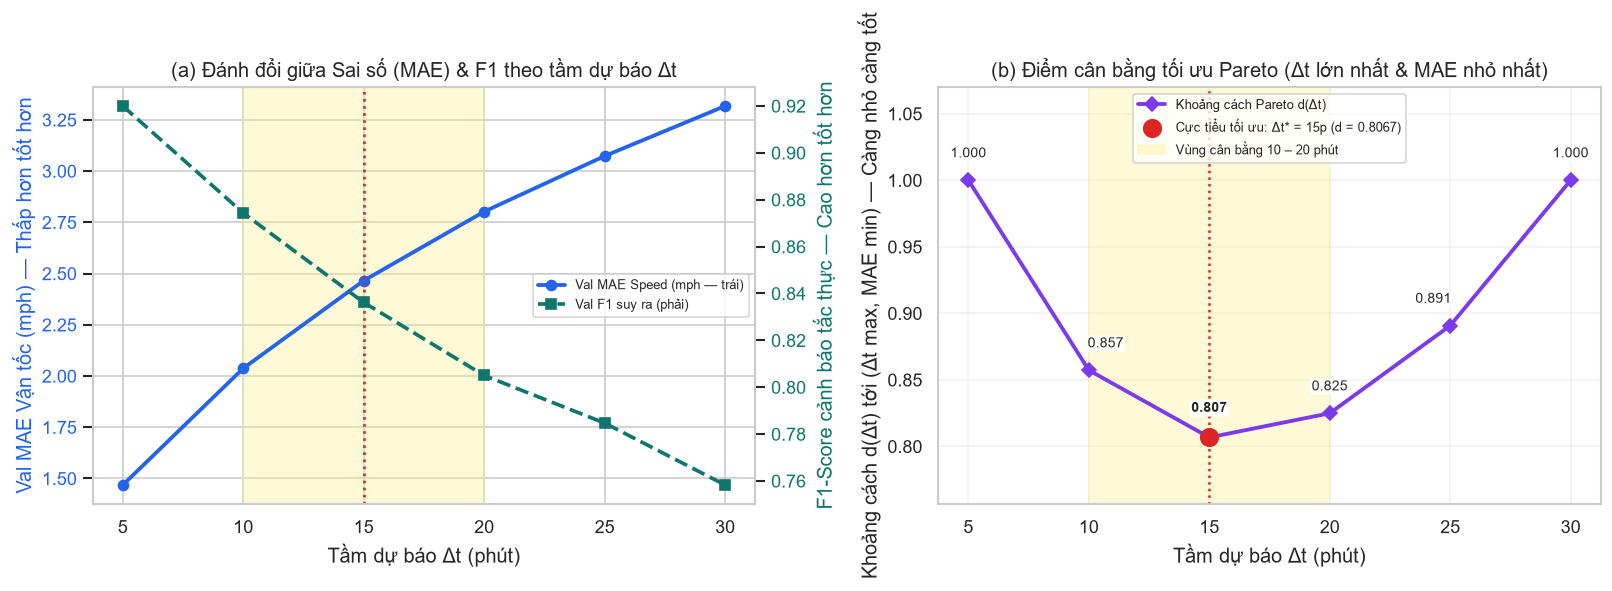

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.6))
dts_p = dt_df["Δt (phút)"]

# (a) Đường cong đánh đổi MAE Speed & F1 suy ra theo Δt
ax = axes[0]
l1 = ax.plot(dts_p, dt_df["Val MAE Speed (mph)"], "o-", color="#2563eb", lw=2.3, label="Val MAE Speed (mph — trái)")
ax.set_xlabel("Tầm dự báo Δt (phút)")
ax.set_ylabel("Val MAE Vận tốc (mph) — Thấp hơn tốt hơn", color="#2563eb")
ax.tick_params(axis="y", labelcolor="#2563eb")
ax.set_xticks(dts_p)
ax.axvspan(10, 20, color="#fef08a", alpha=0.35)
ax.axvline(OPTIMAL_DT_EDA, color="#dc2626", ls=":", lw=1.6)

ax2 = ax.twinx()
l2 = ax2.plot(dts_p, dt_df["Val F1 suy ra"], "s--", color="#0f766e", lw=2.2, label="Val F1 suy ra (phải)")
ax2.set_ylabel("F1-Score cảnh báo tắc thực — Cao hơn tốt hơn", color="#0f766e")
ax2.tick_params(axis="y", labelcolor="#0f766e")
ax2.grid(False)
lines = l1 + l2
ax.legend(lines, [l.get_label() for l in lines], loc="center right", fontsize=8.0, frameon=True)
ax.set_title("(a) Đánh đổi giữa Sai số (MAE) & F1 theo tầm dự báo Δt")

# (b) Khoảng cách tới Điểm Lý tưởng Pareto (Δt max & MAE min)
ax = axes[1]
ax.plot(dts_p, dt_df["Khoảng cách Pareto d(Δt)"], "D-", color="#7c3aed", lw=2.3, markersize=6, label="Khoảng cách Pareto d(Δt)")
ax.scatter([OPTIMAL_DT_EDA], [best_dt_row["Khoảng cách Pareto d(Δt)"]], color="#dc2626", s=110, zorder=5,
           label=f"Cực tiểu tối ưu: Δt* = {OPTIMAL_DT_EDA}p (d = {best_dt_row['Khoảng cách Pareto d(Δt)']:.4f})")
for m_v, d_v in zip(dts_p, dt_df["Khoảng cách Pareto d(Δt)"]):
    dx = 0.7 if m_v == 10 else (-0.7 if m_v == 25 else 0.0)
    dy = 0.015 if m_v != OPTIMAL_DT_EDA else 0.017
    ax.text(m_v + dx, d_v + dy, f"{d_v:.3f}", ha="center", va="bottom", fontsize=8.2,
            fontweight="bold" if m_v == OPTIMAL_DT_EDA else "normal",
            bbox=dict(boxstyle="round,pad=0.14", fc="white", ec="none", alpha=0.82))
ax.axvline(OPTIMAL_DT_EDA, color="#dc2626", ls=":", lw=1.5)
ax.axvspan(10, 20, color="#fef08a", alpha=0.35, label="Vùng cân bằng 10 – 20 phút")
ax.set_xticks(dts_p); ax.set_ylim(dt_df["Khoảng cách Pareto d(Δt)"].min() - 0.05, 1.07)
ax.set(xlabel="Tầm dự báo Δt (phút)", ylabel="Khoảng cách d(Δt) tới (Δt max, MAE min) — Càng nhỏ càng tốt",
       title="(b) Điểm cân bằng tối ưu Pareto (Δt lớn nhất & MAE nhỏ nhất)")
ax.legend(fontsize=8.0, loc="upper center", frameon=True)
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(FIG_DIR / "nb04_optimal_leadtime_pareto.png", dpi=300, bbox_inches="tight")
plt.show()

> **Nhận xét (Xác định tầm dự báo tối ưu $\Delta t^*$ bằng mô hình nhẹ & cực tiểu Pareto):**
>
> * **Quy luật đánh đổi rõ nét theo $\Delta t$:** Khi tăng tầm dự báo từ `5` lên `30 phút` trên tập kiểm định thời gian (`15% Val`, mô hình `HistGradientBoostingRegressor` dùng chung `25` đặc trưng gộp), sai số `Val MAE Speed` tăng đơn điệu từ **`1,4680 mph`** (`R² = 0,9651`, `MAE Occ = 0,0110`, `F1 = 0,9200`) lên **`3,3175 mph`** (`R² = 0,7732`, `MAE Occ = 0,0173`, `F1 = 0,7583`).
>
> * **Điểm cân bằng tối ưu Pareto rơi chính xác tại `Δt* = 15 phút`:** Khoảng cách hình học tới Điểm Lý tưởng (`Δt` max & `MAE` min) đạt **cực tiểu duy nhất tại `Δt* = 15 phút` (`d = 0,8067`)**, với chất lượng dự báo vững (`Val MAE Speed = 2,4654 mph`, `R² = 0,8825`, `MAE Occ = 0,0143`, `Val F1 = 0,8362`). Hai mốc liền kề tạo thành **vùng cân bằng `10 – 20 phút`** (`10p`: `d = 0,8572`, `MAE = 2,0375`, `F1 = 0,8743`; `20p`: `d = 0,8249`, `MAE = 2,8022`, `F1 = 0,8050`), trong khi `5p` và `30p` cùng rơi về hai biên cực đoan (`d = 1,0000`).
>
> * **Sự hội tụ giữa vật lý và mô hình nhẹ:** Mốc tối ưu **`Δt* = 15 phút`** (nằm giữa vùng `10 – 20 phút`) khớp chính xác với **vùng chuyển pha `t - 20` đến `t - 5` phút** đã quan sát ở Mục 2 (`Flow` đạt đỉnh công suất tại `-10p` trước khi gãy pha tại `0p`), vừa đủ xa để can thiệp điều phối giao thông, vừa giữ sai số vận tốc dưới `2,5 mph`.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Khi đã có trọn bộ 4 tham số được kiểm chứng định lượng từ dữ liệu (`Speed < 40 & Occ ≥ 0,15`, `H* = 8`, đồ thị 2 chiều đa nhánh, `Δt* = 15 phút` cùng dải kiểm thử `{5, 10, 15, 20, 30}` phút), ở Bước 05, kiến trúc mô hình học sâu nào (so sánh công bằng từ cục bộ đến đồ thị không gian – thời gian) sẽ khai thác tốt nhất bộ tín hiệu này?

---
## 7. Tổng kết & Bộ Tham số Bàn giao sang Bước 05

Notebook 04 đã kiểm chứng định lượng trọn vẹn 5 khía cạnh của dấu hiệu tiền tắc nghẽn trên **Top 20 điểm nghẽn `PEMS08`** theo đúng tiêu chí tắc nghẽn thực **`(Vận tốc < 40 mph) & (Độ chiếm dụng ≥ 0,15)`**, dùng bước kế tiếp tự nhiên **`Δt = 5 phút`** làm mặc định cho Mục 3–5 và chỉ chốt tầm dự báo tối ưu **`Δt*`** tại Mục 6:

1. **Quỹ đạo pha tiền tắc nghẽn (`n = 3.136` sự cố khởi phát):** `Lưu lượng` đạt đỉnh **`435,2 xe/5p`** tại `t = -10p` rồi sụp mạnh xuống **`407,5 xe/5p`** tại `t = 0p`, trong khi `Độ chiếm dụng` tăng dựng đứng từ `0,185` (`-20p`) → `0,204` (`-5p`) → **`0,253`** (`0p`) và `Vận tốc` gãy từ `46,5` → `42,5` → **`36,9 mph`**. Vùng chuyển pha tập trung rõ nét ở **`t - 20` đến `t - 5` phút**.

2. **Chốt độ dài cửa sổ quá khứ (`H* = 8` bước = `40 phút`):** Kiểm định thuần thống kê `PACF` (`95% CI = 0,0147`) cho thấy cả `Speed` (`0,9770 → 0,0160`) và `Occupancy` (`0,9563 → 0,0236`) cùng vượt ngưỡng liên tục từ `k = 1..8` và cùng cắt xuống dưới ngưỡng ngay tại `k = 9` (`0,0142 / 0,0117`). Trong cửa sổ `H* = 8`, `ROC-AUC` báo bước kế tiếp `t + 5p` giữ rất cao (`Occ`: `0,9334 → 0,8724`; `Speed`: `0,9438 → 0,8392`).

3. **Kiểm chứng độ biến động trong cửa sổ `H* = 8` (`40 phút`, mốc `t + 5p`):** Dao động bất thường (`Std40p`) trước lúc tắc tăng vọt gấp **`5,32 lần`** ở `Occupancy` (`AUC = 0,9321`, `Risk Ratio Top 10% = 35,96x`, `p < 1e-300`) và **`3,79 lần`** ở `Speed` (`AUC = 0,8715`, `RR = 12,28x`, `p < 1e-300`), mạnh hơn rõ rệt so với `Flow` (`1,28 lần`, `AUC = 0,6323`, `RR = 2,06x`). Mức dịch chuyển `Δ40p` giữ ý nghĩa rõ sau khử nhịp ngày (`Occ`: `0,6165`; `Speed`: `0,6316`).

4. **Chốt cấu trúc không gian `Self + Đồ thị 2 chiều đa nhánh` (`18/20` điểm nghẽn có đủ vào/ra; TB `2,72` nhánh vào và `2,44` nhánh ra):** So trực tiếp giá trị cộng thêm trên nền **`Self only`** (`Val PR-AUC = 0,3094`, `Log-Loss = 0,02923` tại `t + 5p`), **`Self + 2 chiều (Mean + Max)`** đạt tốt nhất tuyệt đối (**`PR-AUC = 0,3383`**, tăng **`+9,36%`**; **`Log-Loss = 0,02816`**), vượt có ý nghĩa thống kê cả `Self only` (`LRT χ² = 91,8`, **`p = 2,26e-14`**, cải thiện `13/18` trạm), `Self + Chiều vào` (`0,3308`, **`p = 0,0030`**) lẫn `Self + Chiều ra` (`0,3281`, **`p = 0,0003`**).

5. **Chốt tầm dự báo tối ưu (`Δt* = 15 phút`) bằng mô hình nhẹ & cân bằng Pareto:** Khi gộp toàn bộ `25` đặc trưng đã chứng minh vào mô hình `HistGradientBoostingRegressor` dùng chung (`70/15` Train/Val theo thời gian), khoảng cách hình học tới điểm lý tưởng (`Δt` max & `MAE` min) đạt **cực tiểu duy nhất tại `Δt* = 15 phút` (`d = 0,8067`, `Val MAE Speed = 2,4654 mph`, `R² = 0,8825`, `MAE Occ = 0,0143`, `Val F1 = 0,8362`)**, nằm giữa vùng cân bằng **`10 – 20 phút`** (`d = 0,8572` và `0,8249`).

### Bộ tham số định lượng bàn giao sang Bước 05
| Hạng mục | Giá trị chốt | Cơ sở bằng chứng |
| :--- | :--- | :--- |
| **Tiêu chí nhãn tắc thực** | `(Speed < 40 mph) & (Occ ≥ 0,15)` | Sơ đồ cơ bản 3 biến (Bước 03) |
| **Cửa sổ quá khứ đầu vào (`H*`)** | **`8` bước (`40 phút`)** | `PACF` 95% CI `= 0,0147` cắt tại `k = 9` (Mục 3) |
| **Cấu trúc đồ thị đầu vào** | **`Self` + Đồ thị 2 chiều** (cả nhánh vào & ra) | `Self + 2 chiều` tăng `+9,36%` `PR-AUC`, `p = 2,26e-14` (Mục 5) |
| **Tầm dự báo tối ưu (`Δt*`)** | **Mốc chuẩn `15 phút`** (vùng `10–20p`; dải quét `{5, 10, 15, 20, 30}p`) | Cực tiểu Pareto `d = 0,8067`, khớp vùng chuyển pha (Mục 2 & 6) |

* **Biểu đồ bàn giao (`5` tệp `300 DPI`):** `nb04_phase_trajectory.png`, `nb04_pacf_window_H.png`, `nb04_volatility_before_congestion.png`, `nb04_spatial_multi_edge.png`, `nb04_optimal_leadtime_pareto.png`.

### Câu hỏi nghi vấn chuyển sang Bước 05
> *Với bộ tham số đã chốt từ dữ liệu (`H* = 8` bước, `Self` + đồ thị 2 chiều đa nhánh, mốc trọng tâm `Δt* = 15 phút` và dải quét `{5, 10, 15, 20, 30}` phút), khi thiết kế và so sánh khách quan các nhóm kiến trúc mô hình dự báo từ đơn giản (đường cơ sở, cục bộ tại trạm) đến đồ thị không gian – thời gian, mô hình nào đạt độ chính xác cao nhất và có thể giải thích định lượng đóng góp của từng nhánh đường cũng như từng bước quá khứ hay không?*

---

**Tiếp theo:** [05. Thiết kế, Thử nghiệm Mô hình Dự báo & Giải thích Mô hình (`05_Modeling_and_Explainability.ipynb`)](./05_Modeling_and_Explainability.ipynb)